# Chapter 32 | Worked solutions

*What Changed, and What Remains?*

These twelve solutions ask three connected questions: what information survives, how a prediction accesses it, and what that access costs. A short window can lose an old code; a summary designed for the question can retain it in a small record. Neither outcome is a universal claim about a trained neural architecture.

Exercises 1-4 work through counts and representations, 5-8 inspect the canonical Python stores, and 9-12 develop controlled evaluation designs. Three plots show causal-pair growth, a persistent-history budget, and the exact-answer sweep. All numerical results are teaching calculations or explicit rule outputs, not GPU timings or learned-model benchmarks.

## Setup

Open this notebook inside `transformers-book` and run every cell in order. The canonical helpers use the Python standard library. This expanded notebook also uses NumPy and Matplotlib for plotting and checks. Its written PDF retains all explanations and figures; the notebook PDF also includes code and recorded outputs.

In [1]:
from pathlib import Path
import sys

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch32_perspective"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

In [2]:
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
plt.rcdefaults()
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False})
from examples.ch32_perspective.model import (
    causal_pair_counts, compare_memory, make_history)

## 1. Count permitted pairs

Number queries and keys from 1 to 10. An ordered pair $(q,k)$ is causal when $k\leq q$. Thus $(3,1)$ is allowed but $(1,3)$ looks ahead. Full attention has $1+2+\cdots+10=55$ pairs, including ten self-pairs.

A width-four window permits keys $\max(1,q-3)$ through $q$. The earliest three queries have only 1, 2, and 3 keys. Query 4 has four; queries 5 through 10 also have four but lose progressively older keys. The window total is

$$
1+2+3+7(4)=34.
$$

Equivalently, start with $10(4)=40$ and subtract the three short-row deficits $3+2+1=6$. At length 3 the full and width-four rules coincide. These counts describe permitted connections, not measured runtime. Each pair and each recurrent update contain different arithmetic; the graph compares only the two pair-count rules.

At n=10: (55, 34)


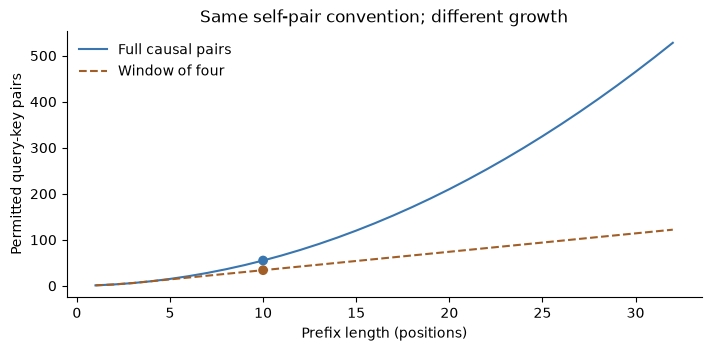

In [3]:
assert causal_pair_counts(10,4) == (55,34)
lengths = np.arange(1,33)
counts = np.array([causal_pair_counts(int(n),4) for n in lengths])
fig,ax=plt.subplots(figsize=(7,3.4),layout="constrained")
ax.plot(lengths,counts[:,0],label="Full causal pairs",color="#3976af")
ax.plot(lengths,counts[:,1],"--",label="Window of four",color="#a25e27")
ax.scatter([10,10],[55,34],color=["#3976af","#a25e27"])
ax.set(xlabel="Prefix length (positions)",ylabel="Permitted query-key pairs",
       title="Same self-pair convention; different growth")
ax.legend(frameon=False)
plt.show()
print("At n=10:", causal_pair_counts(10,4))

## 2. Locate an architectural change

Consider the prefix *the red car*. Changing what is predicted, what is retained, what is read, and how a read is executed are different decisions.

| Decision | Example | Consequence |
| --- | --- | --- |
| Training task | BERT, 2018 public report | Reconstruct selected tokens using surrounding context; the target differs from causal next-token prediction. |
| Stored feature width | MQA, 2019 | Query heads share one key head and one value head, reducing each retained entry's width. |
| Readable positions | Longformer, 2020 | Local and designated global positions determine direct attention access. This pattern need not be causal in an encoder. |
| Execution | FlashAttention, 2022 | Tiling and online softmax reduce transfers and intermediate storage while preserving the attention function up to roundoff. |

MQA retains an entry for every position in full-history use. It changes the multiplier, not linear cache growth. For one layer and one sequence, ordinary KV storage is $nH_{KV}(d_k+d_v)b$ bytes. With $n=1024$, eight stored heads, widths 64 and two bytes per scalar, it is 2 MiB. One KV head needs 0.25 MiB. Doubling history doubles both. These are stored-tensor payloads, not total device memory; MLA requires separate latent/position accounting.

In [4]:
def kv_payload(n, heads, dk=64, dv=64, bytes_per_scalar=2):
    return n*heads*(dk+dv)*bytes_per_scalar
for n in (1024,2048):
    print(f"n={n}: eight KV heads {kv_payload(n,8)/2**20:g} MiB; "
          f"one KV head {kv_payload(n,1)/2**20:g} MiB")
assert kv_payload(1024,8) == 2*2**20
assert kv_payload(1024,1) == 2**18

n=1024: eight KV heads 2 MiB; one KV head 0.25 MiB
n=2048: eight KV heads 4 MiB; one KV head 0.5 MiB


## 3. Find two histories with the same summary

| Event | History 1 | History 2 |
| --- | --- | --- |
| 1 | Code 402 | Code 915 |
| 2 | Route A | Route D |
| 3 | Route B | Route E |
| 4 | Route C | Route C |

The route-only summary ends at C for both streams. A reader receiving only C and the same first-code question has identical inputs, even though the correct answers differ. A deterministic reader must answer identically; a randomized reader has the same answer distribution and cannot guarantee both different answers.

Keep the first code and the current route to answer both questions. The final records are (402,C) and (915,C). Intermediate routes can be discarded for these questions. A code-only summary is insufficient too: changing the final route changes the second answer without changing the code. The information requirement does not demand two physical fields; the values may be packed together.

In [5]:
h1 = make_history(402,["A","B","C"])
h2 = make_history(915,["D","E","C"])
r1,r2 = [compare_memory(h,3) for h in (h1,h2)]
assert r1["route_only"] == r2["route_only"]
assert r1["code_and_route"]["first_code"] == 402
assert r2["code_and_route"]["first_code"] == 915
print("Same route-only result:",r1["route_only"])
print("Code-and-route:",(402,"C"),(915,"C"))

Same route-only result: {'first_code': None, 'current_route': 'C', 'retained_units': 1, 'unit': 'field'}
Code-and-route: (402, 'C') (915, 'C')


With 1000 possible codes and four possible routes, there are $1000(4)=4000$ answer combinations. Exact recovery of both for every combination requires at least 4000 distinct summary states. Since $2^{11}=2048<4000\leq4096=2^{12}$, a fixed-length binary summary needs at least 12 bits, ignoring metadata.

A construction achieves this bound: index codes by $c\in\{0,\ldots,999\}$ and routes by $r\in\{0,1,2,3\}$, then encode $4c+r$. Integer division by 4 recovers $c$ and the remainder recovers $r$. If only the current route mattered, two bits would suffice. This is a finite-alphabet encoding argument, not an estimate of a neural model's useful capacity.

In [6]:
encodings = {4*c+r for c in range(1000) for r in range(4)}
bits = math.ceil(math.log2(len(encodings)))
assert len(encodings)==4000 and bits==12
for c in range(1000):
    for r in range(4):
        assert divmod(4*c+r,4)==(c,r)
print("Distinct answer combinations:",len(encodings))
print("Minimum fixed-length bits:",bits)

Distinct answer combinations: 4000
Minimum fixed-length bits: 12


## 4. Budget persistent history

Each of two full-attention layers stores four scalars per position: together they use $8n$. Three recurrent layers reserve four scalars each: 12 in total. Thus

$$
H(n)=8n+12,\qquad 8n+12\leq92\Longrightarrow n\leq10.
$$

Length 10 uses exactly 92 scalars; length 11 needs 100. With two-byte scalars, the largest allowed full-history example uses 184 bytes.

Replace both attention layers by windows of four and evict old entries. Then $H_w(n)=8\min(n,4)+12$, so the maximum is 44 scalars or 88 bytes. This memory budget imposes no maximum prefix length on that fixed-window accounting, although it changes what is directly retained and says nothing about output quality.

The plot reserves the recurrent state even at length zero. It excludes weights, allocation overhead, temporary activations, and any auxiliary buffers not specified by the exercise. Real recurrent blocks can retain additional convolution or other state. Count all such tensors for an implementation comparison.

Full hybrid at n=10: 184 bytes
Window hybrid maximum: 88 bytes


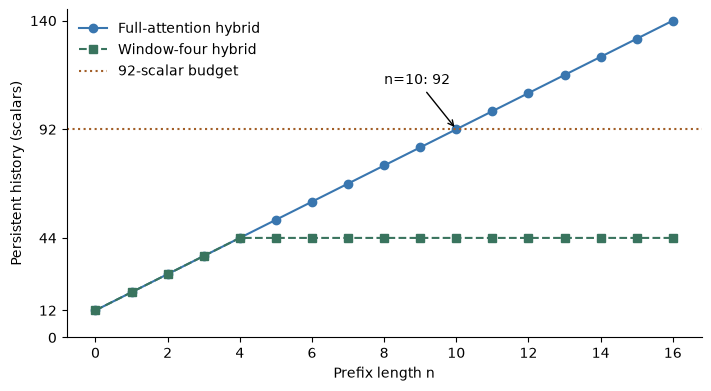

In [7]:
n=np.arange(17)
full=8*n+12
window=8*np.minimum(n,4)+12
assert full[10]==92 and full[11]==100 and max(window)==44
fig,ax=plt.subplots(figsize=(7,3.8),layout="constrained")
ax.plot(n,full,"o-",label="Full-attention hybrid",color="#3976af")
ax.plot(n,window,"s--",label="Window-four hybrid",color="#39745e")
ax.axhline(92,color="#a25e27",linestyle=":",label="92-scalar budget")
ax.set(xlabel="Prefix length n",ylabel="Persistent history (scalars)",
       xticks=range(0,17,2),yticks=[0,12,44,92,140],ylim=(0,145))
ax.annotate("n=10: 92",xy=(10,92),xytext=(8,112),
            arrowprops={"arrowstyle":"->"})
ax.legend(frameon=False,loc="upper left")
plt.show()
print("Full hybrid at n=10:",92*2,"bytes")
print("Window hybrid maximum:",44*2,"bytes")

## 5. Verify a window boundary

At position 4, full causal attention can read keys 1 through 4. A
window of three can read only keys 2, 3, and 4. Key 4 is the query's
own position and takes one of the three slots.

Write each ordered pair as $(q,k)$, with the query first and both
positions counted from one. Full causal attention permits every
$k\leq q$. The window also requires $q-k<3$, so the key can be at the
query itself or up to two positions earlier. We enumerate the pairs
at each requested length and compare the sizes of the lists with
the two counts from `causal_pair_counts`.

In [8]:
from examples.ch32_perspective.model import causal_pair_counts

window_width = 3
print("Length  Full causal  Windowed")
for length in (0, 3, 5):
    full_pairs = [
        (query, key)
        for query in range(1, length + 1)
        for key in range(1, query + 1)
    ]
    window_pairs = [
        (query, key) for query, key in full_pairs
        if query - key < window_width
    ]
    full_count, window_count = causal_pair_counts(length, window_width)
    assert (full_count, window_count) == (
        len(full_pairs), len(window_pairs)
    )
    print(f"{length:>6}  {full_count:>11}  {window_count:>8}")
    if length == 3:
        assert full_pairs == window_pairs
        length_three_pairs = full_pairs

print()
print("Pairs at length 3, under either rule")
print(length_three_pairs)

Length  Full causal  Windowed
     0            0         0
     3            6         6
     5           15        12

Pairs at length 3, under either rule
[(1, 1), (2, 1), (2, 2), (3, 1), (3, 2), (3, 3)]


At length 0 there are no queries, so both counts are 0. At length 3
the queries contribute 1, 2, and 3 pairs for a total of 6. Every pair
fits in the window. At length 5, full attention adds 4 pairs for query
4 and 5 pairs for query 5, giving $6+4+5=15$. The window drops
$(4,1)$, $(5,1)$, and $(5,2)$. Each of those last two queries
contributes 3 pairs to the windowed count, giving $6+3+3=12$.

At length three the complete ordered list is $(1,1),(2,1),(2,2),(3,1),(3,2),(3,3)$. Both rules permit all six pairs.

## 6. Change the window size

Read the code 517, then assign route X, then Y, then Z. At the end
of the stream, the recent window has kept a tail of these four
events. Each new event joins the tail. If the window is already full,
the oldest retained event drops out.

For each width, read `first_code` and `current_route` from
`recent_window`. The history slice shows which events are in the
tail at the end, in the order they arrived.

In [9]:
from examples.ch32_perspective.model import compare_memory, make_history

history = make_history(517, ["X", "Y", "Z"])
expected_answers = {2: (None, "Z"), 3: (None, "Z"), 4: (517, "Z")}

print("Window  first_code  current_route  Retained events")
for width in (2, 3, 4):
    recent = compare_memory(history, width)["recent_window"]
    first_code = recent["first_code"]
    current_route = recent["current_route"]
    assert (first_code, current_route) == expected_answers[width]

    tail = history[-width:]
    assert recent["retained_units"] == len(tail)
    retained = ", ".join(f"{kind}={value}" for kind, value in tail)
    print(
        f"{width:>6}  {str(first_code):>10}  "
        f"{current_route:>13}  {retained}"
    )

Window  first_code  current_route  Retained events
     2        None              Z  route=Y, route=Z
     3        None              Z  route=X, route=Y, route=Z
     4         517              Z  code=517, route=X, route=Y, route=Z


Width 2 keeps Y and Z. Width 3 also keeps X, but the three route
assignments still fill the window and the earlier code has dropped
out. In both cases `first_code` is `None`, meaning the code is
unavailable from the retained events. Width 4 has room for the whole
stream, so `first_code` becomes 517.

Every tail includes Z, the final route assignment. Each assignment
replaces the earlier route, so that one retained event is enough to
answer the current-route question at all three widths.

## 7. Test a history with no route assignments

The delivery starts with code 620 and receives no route assignment.
The history therefore contains one event, `("code", 620)`. The full
archive keeps the event. A window of one also keeps it because it is
the most recent event. The code-and-route summary stores the code in
its code field. The route-only summary creates a field when it sees a
route assignment, so it has zero populated fields here. All four rules
have no route value to return.

Read `first_code`, `current_route`, and the storage count for each
method. The expected answers and counts come from tracing what each
rule keeps.

In [10]:
from examples.ch32_perspective.model import compare_memory, make_history

code_only = make_history(620, [])
assert code_only == (("code", 620),)
code_only_answers = compare_memory(code_only, window=1)

expected_code_only = {
    "full_archive": (620, None, 1, "event"),
    "recent_window": (620, None, 1, "event"),
    "route_only": (None, None, 0, "field"),
    "code_and_route": (620, None, 1, "field"),
}
assert set(code_only_answers) == set(expected_code_only)
print(f"{'Rule':15} {'First code':>10} {'Route':>7} {'Count':>6} Unit")
for rule, expected in expected_code_only.items():
    answer = code_only_answers[rule]
    observed = (
        answer["first_code"],
        answer["current_route"],
        answer["retained_units"],
        answer["unit"],
    )
    assert observed == expected
    first_code, current_route, count, unit = observed
    print(
        f"{rule:15} {str(first_code):>10} {str(current_route):>7} "
        f"{count:6d} {unit}"
    )

Rule            First code   Route  Count Unit
full_archive           620    None      1 event
recent_window          620    None      1 event
route_only            None    None      0 field
code_and_route         620    None      1 field


The output uses `None` for any unavailable answer. Here
`current_route` is `None` for every rule because a route event never
occurred. The route-only summary also reports `first_code=None` even
though the code event occurred. That summary has no field for it.
For an example of eviction, append a single route assignment to the
same code and keep the window at one. The route event takes the only
slot, so the window's code answer becomes `None`. The same marker
covers information that was absent from the stream and information
that the rule left out of its retained state.

Zero is a valid code value, not an absence marker. Test absence with `is None` rather than truthiness. After adding one route at window one, the earlier code has been evicted from that window, while the two-field summary still retains it. The same output marker does not distinguish omission, eviction, and an event that never occurred; inspect the stream and storage rule.

In [11]:
zero_answers=compare_memory(make_history(0,[]),window=1)
assert zero_answers["full_archive"]["first_code"] == 0
assert zero_answers["full_archive"]["first_code"] is not None
evicted=compare_memory(make_history(0,["A"]),window=1)
assert evicted["recent_window"]["first_code"] is None
assert evicted["code_and_route"]["first_code"] == 0
print("Valid zero:",zero_answers["full_archive"]["first_code"])
print("Window after route A:",evicted["recent_window"])

Valid zero: 0
Window after route A: {'first_code': None, 'current_route': 'A', 'retained_units': 1, 'unit': 'event'}


## 8. Compare the storage records

With one route update the history is a code followed by route A.
With eight updates it contains the code and routes A through H in
order. Each sweep entry uses two different starting codes and the same
routes. Changing the code changes the value of the first event while
leaving the number of events and populated fields the same.

The archive keeps both events at one update and all nine at eight
updates. The three-event window keeps both events in the first case
and only the final three route events in the second. The route-only
summary overwrites one route field on every assignment. The
code-and-route summary also keeps the original code, so both its
fields are populated as soon as the first route arrives.

Run the chapter's module with the notebook kernel's Python and pass
`--output` as in the listing. The JSON goes to a temporary directory.
Read `retained_units` and `unit` from the one-update and eight-update
records in `accuracy_sweep` and check them against those counts.

In [12]:
import json
import subprocess
from tempfile import TemporaryDirectory

with TemporaryDirectory() as temp_dir:
    json_path = Path(temp_dir) / "ch32.json"
    subprocess.run(
        [
            sys.executable,
            "-m",
            "examples.ch32_perspective.run_examples",
            "--output",
            str(json_path),
        ],
        cwd=repo_root,
        check=True,
        stdout=subprocess.DEVNULL,
    )
    report = json.loads(json_path.read_text(encoding="utf-8"))

assert report["window"] == 3
methods_by_updates = {
    row["route_updates"]: row["methods"] for row in report["accuracy_sweep"]
}

In [13]:
expected_storage = {
    "full_archive": (2, 9, "event"),
    "recent_window": (2, 3, "event"),
    "route_only": (1, 1, "field"),
    "code_and_route": (2, 2, "field"),
}
one_update = methods_by_updates[1]
eight_updates = methods_by_updates[8]
assert set(one_update) == set(eight_updates) == set(expected_storage)

print(f"{'Rule':15} {'1 update':>8} {'8 updates':>9} Unit")
for rule, expected in expected_storage.items():
    first = one_update[rule]
    last = eight_updates[rule]
    unit = first["unit"]
    assert unit == last["unit"]
    first_count = first["retained_units"]
    last_count = last["retained_units"]
    assert (first_count, last_count, unit) == expected
    print(f"{rule:15} {first_count:8d} {last_count:9d} {unit}")

Rule            1 update 8 updates Unit
full_archive           2         9 event
recent_window          2         3 event
route_only             1         1 field
code_and_route         2         2 field


The two event stores count entries in a history. For example, the
archive keeps a separate entry for each route assignment, with the
event's kind and value in a tuple. A summary counts populated fields
in a dictionary. Its route field holds only the last assigned value.
Two events and two fields describe equal counts of different units.
A byte comparison needs a specified representation and accounting
boundary. In Python, container overhead and whether keys and values
are shared affect how many bytes each store occupies. These JSON
records report logical counts for the stores.

A populated Python field can hold an arbitrarily large integer or a variable-length string. Constant field count alone does not establish constant bytes. A byte audit must specify bounded values or measure recursively with a clear policy for shared objects; a shallow container size omits referenced payloads.

The plot below uses the canonical sweep's exact-answer results. Each point summarizes two supplied histories, not an estimate of a trained model's accuracy. At one and two route updates the three-event window still contains the code. At four and eight it does not. All stores answer the latest-route question in these cases. The two-field summary works because its fields were selected for exactly these questions.

Window first-code fractions: [1.0, 1.0, 0.0, 0.0]


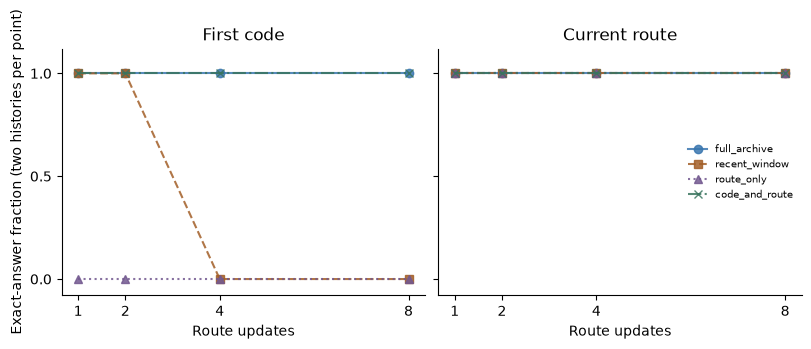

In [14]:
updates=[row["route_updates"] for row in report["accuracy_sweep"]]
fig,axes=plt.subplots(1,2,figsize=(8,3.2),sharey=True,layout="constrained")
styles=[("full_archive","o-","#3976af"),("recent_window","s--","#a25e27"),
        ("route_only","^:","#72588f"),("code_and_route","x-.","#39745e")]
for ax,metric,title in zip(axes,["first_code_accuracy","current_route_accuracy"],
                           ["First code","Current route"]):
    for method,style,color in styles:
        values=[row["methods"][method][metric] for row in report["accuracy_sweep"]]
        ax.plot(updates,values,style,label=method,color=color,alpha=.85)
    ax.set(title=title,xlabel="Route updates",xticks=updates,yticks=[0,.5,1],
           ylim=(-.08,1.12))
axes[0].set_ylabel("Exact-answer fraction (two histories per point)")
axes[1].legend(fontsize=7,frameon=False,loc="center right")
plt.show()
print("Window first-code fractions:",
      [row["methods"]["recent_window"]["first_code_accuracy"]
       for row in report["accuracy_sweep"]])

## 9. Separate delay from interference

Begin with a code for delivery P and end with a question asking for that code. For delay, insert 0, 8, 32, or 128 unrelated messages, keeping competitor count fixed at zero. Repeat matched sets with varied target codes and report actual token distance; a message is not necessarily one token.

For interference, keep the total length and the target/question offsets fixed. Replace 0, 4, 8, or 16 of 32 fixed-size filler slots by plausible codes for other deliveries. Match their token lengths after formatting with the model's tokenizer. Balance target and distractor values and vary distractor positions. Count examples and exact-answer accuracy by condition; classify errors as copied competitors, other wrong answers, or missing responses.

Inspect the final model input after formatting and truncation. A removed target cannot test recall of visible evidence. A decline with fixed competitor count suggests sensitivity to separation; a rise in copied competitors at fixed length suggests interference. Neither pattern alone identifies an internal neural mechanism.

The audit below uses abstract one-position symbols to isolate the experimental geometry. It does not assert that real text has equal token lengths. A real experiment must repeat the checks on actual token IDs.

In [15]:
def abstract_history(filler_count, competitor_count):
    assert 0 <= competitor_count <= filler_count
    fillers=["OTHER_CODE"]*competitor_count + ["UNRELATED"]*(filler_count-competitor_count)
    return ["TARGET_CODE"] + fillers + ["QUESTION"]
delay=[abstract_history(n,0) for n in (0,8,32,128)]
interference=[abstract_history(32,k) for k in (0,4,8,16)]
assert [len(h) for h in delay] == [2,10,34,130]
assert all(len(h)==34 and h[0]=="TARGET_CODE" and h[-1]=="QUESTION"
           for h in interference)
print("Delay lengths:",[len(h) for h in delay])
print("Fixed-length competitor counts:",
      [h.count("OTHER_CODE") for h in interference])

Delay lengths: [2, 10, 34, 130]
Fixed-length competitor counts: [0, 4, 8, 16]


## 10. Compose an update and a retrieval

Store addresses A=12 Oak Street, B=95 Pine Street and C=7 Elm Street. Then activate A, C and B, and finish with *Prepare the active delivery*. Ask for the final active delivery's address. The active ID is B, so the answer is 95 Pine Street. The final message supplies neither the ID nor the address.

One sufficient representation stores an address map and the current active ID. An archive can also find the latest activation and retrieve the matching address. Storing only B loses the address; storing only the last address returns C's address instead.

Create a matched stream that changes only B's earlier address to 40 Maple Street. Keep the final activation and last message identical: the answer must change. In another pair, keep addresses fixed and change the last activation to A; the answer becomes 12 Oak Street. Randomize addresses and activation order so the active ID is not systematically tied to the most recently stored address.

Score the address task directly. In a separate diagnostic call, ask for the active ID to distinguish a tracking failure from a retrieval failure. The explicit rule below illustrates this composition; it extends the event vocabulary locally and does not change the canonical two-question helper.

In [16]:
def active_address(events):
    addresses={}
    active=None
    for event in events:
        if event[0]=="address":
            addresses[event[1]]=event[2]
        elif event[0]=="activate":
            active=event[1]
        elif event[0]!="prepare":
            raise ValueError("Unknown teaching event")
    return active, addresses.get(active)
events=[("address","A","12 Oak Street"),("address","B","95 Pine Street"),
        ("address","C","7 Elm Street"),("activate","A"),
        ("activate","C"),("activate","B"),("prepare",)]
assert active_address(events)==("B","95 Pine Street")
print("Original:",active_address(events))

Original: ('B', '95 Pine Street')


In [17]:
changed_address=list(events)
changed_address[1]=("address","B","40 Maple Street")
changed_active=list(events)
changed_active[5]=("activate","A")
assert changed_address[-2:] == events[-2:]
assert changed_active[-1] == events[-1]
assert active_address(changed_address)==("B","40 Maple Street")
assert active_address(changed_active)==("A","12 Oak Street")
print("Changed earlier address:",active_address(changed_address))
print("Changed final activation:",active_address(changed_active))

Changed earlier address: ('B', '40 Maple Street')
Changed final activation: ('A', '12 Oak Street')


## 11. Plan an ablation

Compare a causal window-attention stack with a hybrid that replaces a fixed subset of its mixers by a specified recurrent mixer. Preserve window width $w$ in the remaining attention layers, along with tokenizer, depth, feature width, feed-forward blocks and prediction head. Train on the same stream generator and token budget, with matched seeds and optimizer protocol. Report parameter count and actual training compute: mixer replacement can change both, so equal tokens need not mean equal FLOPs.

Test both first-code retrieval and active-delivery address retrieval, below and above the window length, with held-out histories and answer combinations. Vary competing codes separately from delay. Score the two tasks separately using an identical output format and validation procedure.

Use the same device, runtime, batch size, precision, prompt lengths and continuation lengths. Warm up kernels and synchronize device boundaries. Measure prefill through availability of the first output scores; measure subsequent incremental decode separately with existing caches. A shared prescribed continuation can equalize timing work, but teacher-forced timing is distinct from a free-generation quality test. Report median and tail latency over repeated runs.

Count all persistent tensors per sequence, including attention KV, recurrent state and auxiliary convolution buffers. Report weights and peak working memory separately. With five layers each storing four scalars per retained position, an all-window example uses $20\min(n,w)$ scalars. Replacing three by four-scalar recurrent states gives $8\min(n,w)+12$. At $w=4$ their plateaus are 80 and 44 scalars. These illustrative dimensions are not a claim about actual model layers.

Even perfectly measured improvements apply to the chosen mixer, placement, task, optimization and hardware. An equal-parameter or equal-compute experiment may require a separate design; it cannot silently be inferred from equal depth and width. Report quality, latency and bytes together.

In [18]:
for n in (1,4,10):
    all_window=20*min(n,4)
    hybrid=8*min(n,4)+12
    print(f"n={n}: all-window {all_window} scalars; hybrid {hybrid} scalars")
assert 20*4==80 and 8*4+12==44
print("Toy accounting only; no neural model was trained or timed.")

n=1: all-window 20 scalars; hybrid 20 scalars
n=4: all-window 80 scalars; hybrid 44 scalars
n=10: all-window 80 scalars; hybrid 44 scalars
Toy accounting only; no neural model was trained or timed.


## 12. Transfer the evaluation idea

Use a three-day shop forecast from Chapter 28. A weather column that gets overwritten with the eventual observed weather can give a historical backtest information unavailable at the forecast origin. Keep target-valid date separate from forecast issue and receipt times.

Split training, validation and test chronologically; all target days of a window must lie in its assigned split. At each origin, select only forecasts issued and received by the cutoff, for the relevant future target date. Fit transformations on training data and freeze settings after validation. A Monday prediction for Wednesday cannot use a Tuesday weather update or Wednesday's observed weather.

Create a paired availability check. Copy the archived records and change only values whose issue or receipt times make them unavailable at the origin. Preserve timestamps, available records, target sales and model settings. Correct as-of features, and deterministic predictions built from them, should be unchanged. Record selected weather IDs as well as values; equal values can hide selection of a wrong version.

The fixture below includes a forecast issued before the origin but received afterward, as well as a future-issued update. Both are unavailable. Mutating their values must leave the Monday feature unchanged. This tests the specified fixture, not every possible source of leakage.

After availability checks, evaluate as-issued forecasts against actual sales with MAE by horizon 1, 2 and 3, and report missing-version counts. The invariance test checks the information boundary; the rolling score measures prediction quality within it.

In [19]:
from datetime import datetime
origin=datetime(2026,1,5,8)
records=[
    dict(id="available",issue=datetime(2026,1,5,6),
         received=datetime(2026,1,5,7),value=20),
    dict(id="late_receipt",issue=datetime(2026,1,5,7),
         received=datetime(2026,1,5,9),value=22),
    dict(id="future_issue",issue=datetime(2026,1,6,6),
         received=datetime(2026,1,6,7),value=24)]
# All rows forecast the same target date in this fixture.
def as_of(rows, cutoff):
    eligible=[r for r in rows if r["issue"]<=cutoff and r["received"]<=cutoff]
    selected=max(eligible,key=lambda r:r["issue"])
    return selected["id"],selected["value"]
mutated=[dict(r) for r in records]
for row in mutated:
    if row["issue"]>origin or row["received"]>origin:
        row["value"]=-999
assert as_of(records,origin)==as_of(mutated,origin)==("available",20)
print("Original and mutated unavailable records select:",as_of(records,origin))

Original and mutated unavailable records select: ('available', 20)
